In [48]:
import random
random.seed(42)

import torch
import time
import os

import numpy as np
import pyomo.environ as pyo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from pyomo.environ import *
from utils import generate_simple_synthetic_data, const_embed, load_case_study_data, generate_data_by_ids
from trainer import Trainer

np.random.seed(43)

LOAD_CASE_STUDY = False
DATA_BY_ID = True

In [49]:
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    X, y, val_ind, test_ind = load_case_study_data()

elif DATA_BY_ID:
    print("Loading data by IDs...")
    df = generate_data_by_ids(n_ids=100, n_prices_per_id=100, k=0.2)
    X = df[['id', 'x1', 'x2', 'price']]
    y = df['y']
    #y = round(df['y'])
    print(X.head())
    print(y.head())

else:
    X, y, true_mean, true_std = generate_simple_synthetic_data(n_samples=1000)
    print(X.head())
    print(y.head())


Loading data by IDs...
   id            x1            x2          price
0   1  0.3745401188  0.0314291857  22.8406329231
1   1  0.3745401188  0.0314291857  11.6827992999
2   1  0.3745401188  0.0314291857  13.2325742819
3   1  0.3745401188  0.0314291857  27.9710837705
4   1  0.3745401188  0.0314291857  22.1285811932
0    0.9606573593
1    2.4978501204
2    4.3949269251
3    0.5669195994
4    0.0000000000
Name: y, dtype: float64


In [50]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

'''model_config = {
    'hidden_layers': 1,
    'hidden_size': 5,
    'drop': 0.2
    }

training_config = {
    'lr': 0.01,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500,
    'patience': 20
    }'''

config = {
    # Model config
    'hidden_layers': 1,
    'hidden_size': 15,
    'drop': 0.00,

    # Training config
    'lr': 0.001,
    'wd': 0,
    'batchsize': 64,
    'iters': 5000,
    'patience': 100
}

trainer = Trainer(X, y, config, device=device)

if LOAD_CASE_STUDY:
    trainer.set_data_partitions(X_train=X[(~X.index.isin(val_ind)) & (~X.index.isin(test_ind))], y_train=y[(~y.index.isin(val_ind)) & (~y.index.isin(test_ind))], X_val=X[X.index.isin(val_ind)], y_val=y[y.index.isin(val_ind)], X_test=X[X.index.isin(test_ind)], y_test=y[y.index.isin(test_ind)])
elif not DATA_BY_ID:
    trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)
else:
    trainer = Trainer(X, y, config, device=device, id_col='id')
    trainer.create_data_partitions_by_id(val_size=0.2, test_size=0.2, random_state=42)
    #mean_price = trainer.X.loc[trainer.train_indices]['price'].mean()
    

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

X_train shape:  (6000, 3)
X_val shape:  (2000, 3)
X_test shape:  (2000, 3)


In [51]:
trainer.model

distModel(
  (input_layer): Linear(in_features=3, out_features=15, bias=True)
  (hidden_layers): ModuleList(
    (0): Linear(in_features=15, out_features=15, bias=True)
  )
  (output_mean_layer): Linear(in_features=15, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=15, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
)

In [52]:
trainer.train()

trainer.test()

Validation loss improved from inf to 64.4629 in epoch 1. Saving model...
Epoch 1/5000 - Train Loss: 36822.4688, Val Loss: 64.4629
Validation loss improved from 64.4629 to 62.8734 in epoch 2. Saving model...
Validation loss improved from 62.8734 to 61.0483 in epoch 3. Saving model...
Validation loss improved from 61.0483 to 59.3590 in epoch 4. Saving model...
Validation loss improved from 59.3590 to 57.6862 in epoch 5. Saving model...
Validation loss improved from 57.6862 to 55.9716 in epoch 6. Saving model...
Validation loss improved from 55.9716 to 54.2122 in epoch 7. Saving model...
Validation loss improved from 54.2122 to 52.4174 in epoch 8. Saving model...
Validation loss improved from 52.4174 to 50.5490 in epoch 9. Saving model...
Validation loss improved from 50.5490 to 48.5991 in epoch 10. Saving model...
Validation loss improved from 48.5991 to 46.4789 in epoch 11. Saving model...
Epoch 11/5000 - Train Loss: 52.6157, Val Loss: 46.4789
Validation loss improved from 46.4789 to 44

In [12]:
#trainer.predict(X=trainer.X_test)

In [53]:
trainer.evaluate_gaussian_nll()
trainer.evaluate_standardized_residuals()

Baseline Gaussian NLL Loss: 0.5341
Model Gaussian NLL Loss: -0.9147
KS test against N(0,1): statistic = 0.0152, p-value = 0.7404
✅ The standardized residuals do not significantly differ from a standard normal distribution — model variance estimates appear well-calibrated.
Saved: residual_diagnostics\z_histogram.png
Saved: residual_diagnostics\z_qqplot.png


(np.float64(0.015175537291972692), np.float64(0.7403746753693037))

In [33]:
'''# Inputs
x = np.array([[-1.266313, -0.405118, 0.612491]])

# Extract weights from model
state_dict = trainer.model.state_dict()
w0 = state_dict['input_layer.weight'].cpu().numpy()
b0 = state_dict['input_layer.bias'].cpu().numpy()

w1 = state_dict['hidden_layers.0.weight'].cpu().numpy()
b1 = state_dict['hidden_layers.0.bias'].cpu().numpy()

w_mean = state_dict['output_mean_layer.weight'].cpu().numpy()
b_mean = state_dict['output_mean_layer.bias'].cpu().numpy()

w_sd = state_dict['output_sd_layer.weight'].cpu().numpy()
b_sd = state_dict['output_sd_layer.bias'].cpu().numpy()

# Manual forward pass
def relu(x): return np.maximum(0, x)

h0 = relu(x.dot(w0.T) + b0)
h1 = relu(h0.dot(w1.T) + b1)
mean = h1.dot(w_mean.T) + b_mean
sd = relu(h1.dot(w_sd.T) + b_sd)

print("Manual mean:", mean)
print("Manual std:", sd)'''

'# Inputs\nx = np.array([[-1.266313, -0.405118, 0.612491]])\n\n# Extract weights from model\nstate_dict = trainer.model.state_dict()\nw0 = state_dict[\'input_layer.weight\'].cpu().numpy()\nb0 = state_dict[\'input_layer.bias\'].cpu().numpy()\n\nw1 = state_dict[\'hidden_layers.0.weight\'].cpu().numpy()\nb1 = state_dict[\'hidden_layers.0.bias\'].cpu().numpy()\n\nw_mean = state_dict[\'output_mean_layer.weight\'].cpu().numpy()\nb_mean = state_dict[\'output_mean_layer.bias\'].cpu().numpy()\n\nw_sd = state_dict[\'output_sd_layer.weight\'].cpu().numpy()\nb_sd = state_dict[\'output_sd_layer.bias\'].cpu().numpy()\n\n# Manual forward pass\ndef relu(x): return np.maximum(0, x)\n\nh0 = relu(x.dot(w0.T) + b0)\nh1 = relu(h0.dot(w1.T) + b1)\nmean = h1.dot(w_mean.T) + b_mean\nsd = relu(h1.dot(w_sd.T) + b_sd)\n\nprint("Manual mean:", mean)\nprint("Manual std:", sd)'

In [54]:
cons = trainer.constraint_build()
cons.to_csv('constraints.csv')

In [55]:
cons = pd.read_csv('constraints.csv', index_col=0)
pd.set_option('display.precision', 10)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,node_7,node_8,node_9,node_10,node_11,node_12,node_13,node_14
0,0.3112883000,0,0,-0.435884700,-0.2625150700,0.384527270,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.5754453000,0,1,-0.282310700,0.1645416500,0.441655280,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-0.5424863700,0,2,-0.053351650,-0.1281755700,0.528660830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.1949815300,0,3,0.030675747,0.1988159700,-0.186785150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.3199049000,0,4,-0.542055960,-0.0510530320,-0.253502100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,-0.0378838330,0,5,-0.338904050,-0.4449209000,0.454421370,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,-0.2635874200,0,6,-0.493965720,0.0943576200,0.100666970,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.4488714000,0,7,-0.602574900,0.2324031600,0.104984894,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,-0.1604739900,0,8,0.485620230,-0.2381596100,-0.047736198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.3480825700,0,9,-0.950897600,-0.8796831400,0.120260290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:

'''#contextual_var = trainer.X_test
contextual_var = trainer.X_test.iloc[[0]]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var'''

'#contextual_var = trainer.X_test\ncontextual_var = trainer.X_test.iloc[[0]]\ncontextual_var.reset_index(drop=True, inplace=True)\ncontextual_var'

In [37]:
'''row = pd.DataFrame([{
    'x1': -1.266313,
    'x2': -0.405118,
    'price': 30.0
}])

def preict_one_row(row):
    # Predict
    mean_pred, sd_pred = trainer.predict(row, unscale=True)
    print("Mean prediction:", mean_pred)
    print("Standard deviation prediction:", sd_pred)

preict_one_row(row)'''

'row = pd.DataFrame([{\n    \'x1\': -1.266313,\n    \'x2\': -0.405118,\n    \'price\': 30.0\n}])\n\ndef preict_one_row(row):\n    # Predict\n    mean_pred, sd_pred = trainer.predict(row, unscale=True)\n    print("Mean prediction:", mean_pred)\n    print("Standard deviation prediction:", sd_pred)\n\npreict_one_row(row)'

In [56]:
def model_definition(contextual_var, n_sc, n_preds, integer_demand=False, mean_price=None, mean_price_by_id=None, P_max=30):
    model = pyo.ConcreteModel()
    
    model.N = pyo.RangeSet(0,n_preds-1)
    model.W = pyo.RangeSet(1,n_sc) # scenarios

    if mean_price_by_id is not None:
        model.mean_price_by_id = pyo.Param(model.N, initialize=mean_price_by_id)


    pi = [1/n_sc for i in range(n_sc)]

    model.var_ind = pyo.Set(initialize=contextual_var.columns.sort_values())

    model.x = pyo.Var(model.var_ind, model.N) # price

    model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals)
    if integer_demand:
        model.y_int = pyo.Var(model.N, model.W, domain=pyo.Integers)

    model.rent = pyo.Var(model.W, within=pyo.Reals) # rentabilidad per scenario

    #definition of the objective function
    def obj_expression(model):
        return sum(pi[w-1] * model.rent[w] for w in model.W)
    model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)

    #################
    ## Constraints ##
    #################

    if integer_demand:
        # rentability constraint integer y
        def rent_expression_int(model, w):
            return model.rent[w] == sum(model.y_int[n, w]*model.x['price',n] for n in model.N)
        model.rent_expression_int = pyo.Constraint(model.W, rule=rent_expression_int)  

        # integer demand constraint
        # Upper bound constraint
        def round_y_upper(model, n, w):
            return model.y_int[n, w] <= model.y['demand', n, w] + 0.5
        model.round_y_upper = pyo.Constraint(model.N, model.W, rule=round_y_upper)

        # Lower bound constraint
        def round_y_lower(model, n, w):
            return model.y_int[n, w] >= model.y['demand', n, w] - 0.5
        model.round_y_lower = pyo.Constraint(model.N, model.W, rule=round_y_lower)
    else:
        # rentability constraint continuous y
        def rent_expression(model, w):
            return model.rent[w] == sum(model.y['demand', n, w]*model.x['price',n] for n in model.N)
        model.rent_expression = pyo.Constraint(model.W, rule=rent_expression)

    
    #constraint for fixing contextual information
    def contextual_info(model,x_ind,n):
        if x_ind=='price':
            return pyo.Constraint.Skip
        else:
            return model.x[x_ind,n] == contextual_var.loc[n,x_ind]
    model.const9 = pyo.Constraint(model.var_ind, model.N, rule=contextual_info)

    # max price constraint for each price
    def max_price_expression(model, n):
        return model.x['price', n] <= P_max

    model.max_price_expression = pyo.Constraint(model.N, rule=max_price_expression)

    def min_price_expression(model, n):
        return model.x['price', n] >= 0
    model.min_price_expression = pyo.Constraint(model.N, rule=min_price_expression)

    if mean_price is not None:
        # price increase of 2% with respect the mean price
        def price_increase_expression(model):
            return sum(model.x['price', n] for n in model.N)/len(model.N) >= mean_price * 1.02
        model.price_increase_expression = pyo.Constraint(rule=price_increase_expression)

        if mean_price_by_id is not None:
            # price can't increase more than 5% with respect the mean price offered to this client in the past
            def price_increase_by_id_expression(model, n):
                return model.x['price', n] <= model.mean_price_by_id[n] * 1.05

            model.price_increase_by_id_expression = pyo.Constraint(model.N, rule=price_increase_by_id_expression)

    return model


In [57]:
n_preds = 5
n_sc =  50

if DATA_BY_ID:
    ids = trainer.test_ids[:n_preds]
    contextual_var = trainer.X[trainer.X['id'].isin(ids)]
    contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')

    test_df = trainer.X.loc[trainer.test_indices]
    mean_price_by_id  = test_df.groupby('id')['price'].mean()

    mean_price_by_id = mean_price_by_id.loc[ids]

    mean_price_by_id = dict(enumerate(mean_price_by_id))

    mean_price = test_df['price'].mean()
    print("mean_price_by_id:", mean_price_by_id)
    print("mean_price:", mean_price)
else:
    contextual_var = trainer.X[trainer.X.index.isin(trainer.test_indices)]
    contextual_var = contextual_var.iloc[:n_preds]

contextual_var.reset_index(drop=True, inplace=True)
print(contextual_var)

mean_price_by_id: {0: 20.352026614944887, 1: 20.85524641573995, 2: 20.92396588499967, 3: 19.132052581687752, 4: 20.096167148658566}
mean_price: 20.038250723039035
           price            x1            x2
0  22.8406329231  0.3745401188  0.0314291857
1  27.7749615974  0.1560186404  0.9075664739
2  19.7779566358  0.0205844943  0.2897514529
3  13.9033303444  0.1834045099  0.8714605902
4  15.0571623650  0.3042422430  0.8036720769


In [40]:
'''n_preds = 3
n_sc =  30

contextual_var = trainer.X_test.iloc[:n_preds]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var'''

'n_preds = 3\nn_sc =  30\n\ncontextual_var = trainer.X_test.iloc[:n_preds]\ncontextual_var.reset_index(drop=True, inplace=True)\ncontextual_var'

In [59]:
model = model_definition(contextual_var, n_sc, n_preds, mean_price=mean_price, mean_price_by_id=mean_price_by_id, integer_demand=True)
#model = model_definition(contextual_var, n_sc, n_preds)
const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

In [60]:
opt = pyo.SolverFactory('gurobi_direct')
opt.options['threads'] = 0
opt.options['NonConvex'] = 2
results = opt.solve(model, tee=True)

Set parameter OutputFlag to value 1
Set parameter Threads to value 0
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Non-default parameters:
NonConvex  2

Optimize a model with 1236 rows, 875 columns and 5390 nonzeros
Model fingerprint: 0x4a0a7a2b
Model has 50 quadratic constraints
Variable types: 475 continuous, 400 integer (150 binary)
Coefficient statistics:
  Matrix range     [2e-04, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [2e-02, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [7e-03, 1e+03]
Presolve removed 706 rows and 584 columns
Presolve time: 0.01s
Presolved: 975 rows, 515 columns, 3179 nonzeros
Presolved model has 217 bilinear constraint(s)

Solving non-convex MIQCP

Variable types: 2

In [43]:
'''print(value(model.x['price', 0]))
print((value(model.x['price', 0]) * trainer.X_std[0]) + trainer.X_mean[0])
print((value(model.x['price', 0] - trainer.X_mean[0])) / trainer.X_std[0])'''

"print(value(model.x['price', 0]))\nprint((value(model.x['price', 0]) * trainer.X_std[0]) + trainer.X_mean[0])\nprint((value(model.x['price', 0] - trainer.X_mean[0])) / trainer.X_std[0])"

In [61]:
for c in model.component_objects(Constraint, active=True):
    print(f"Constraint component: {c.name}")
    for index in c:
        print(f"  {index}: {c[index].expr}")

Constraint component: rent_expression_int
  1: rent[1]  ==  y_int[0,1]*x[price,0] + y_int[1,1]*x[price,1] + y_int[2,1]*x[price,2] + y_int[3,1]*x[price,3] + y_int[4,1]*x[price,4]
  2: rent[2]  ==  y_int[0,2]*x[price,0] + y_int[1,2]*x[price,1] + y_int[2,2]*x[price,2] + y_int[3,2]*x[price,3] + y_int[4,2]*x[price,4]
  3: rent[3]  ==  y_int[0,3]*x[price,0] + y_int[1,3]*x[price,1] + y_int[2,3]*x[price,2] + y_int[3,3]*x[price,3] + y_int[4,3]*x[price,4]
  4: rent[4]  ==  y_int[0,4]*x[price,0] + y_int[1,4]*x[price,1] + y_int[2,4]*x[price,2] + y_int[3,4]*x[price,3] + y_int[4,4]*x[price,4]
  5: rent[5]  ==  y_int[0,5]*x[price,0] + y_int[1,5]*x[price,1] + y_int[2,5]*x[price,2] + y_int[3,5]*x[price,3] + y_int[4,5]*x[price,4]
  6: rent[6]  ==  y_int[0,6]*x[price,0] + y_int[1,6]*x[price,1] + y_int[2,6]*x[price,2] + y_int[3,6]*x[price,3] + y_int[4,6]*x[price,4]
  7: rent[7]  ==  y_int[0,7]*x[price,0] + y_int[1,7]*x[price,1] + y_int[2,7]*x[price,2] + y_int[3,7]*x[price,3] + y_int[4,7]*x[price,4]
  8: r

In [45]:
'''# Inputs
x = np.array([[-1.266313, -0.405118, 0.612491]])

# Extract weights from model
state_dict = trainer.model.state_dict()
w0 = state_dict['input_layer.weight'].cpu().numpy()
b0 = state_dict['input_layer.bias'].cpu().numpy()

#w1 = state_dict['hidden_layers.0.weight'].cpu().numpy()
#b1 = state_dict['hidden_layers.0.bias'].cpu().numpy()

w_mean = state_dict['output_mean_layer.weight'].cpu().numpy()
b_mean = state_dict['output_mean_layer.bias'].cpu().numpy()

w_sd = state_dict['output_sd_layer.weight'].cpu().numpy()
b_sd = state_dict['output_sd_layer.bias'].cpu().numpy()

# Manual forward pass
def relu(x): return np.maximum(0, x)

h0 = relu(x.dot(w0.T) + b0)
#h1 = relu(h0.dot(w1.T) + b1)
mean = h0.dot(w_mean.T) + b_mean
sd = relu(h0.dot(w_sd.T) + b_sd)

print("Manual mean:", mean)
print("Manual std:", sd)'''

'# Inputs\nx = np.array([[-1.266313, -0.405118, 0.612491]])\n\n# Extract weights from model\nstate_dict = trainer.model.state_dict()\nw0 = state_dict[\'input_layer.weight\'].cpu().numpy()\nb0 = state_dict[\'input_layer.bias\'].cpu().numpy()\n\n#w1 = state_dict[\'hidden_layers.0.weight\'].cpu().numpy()\n#b1 = state_dict[\'hidden_layers.0.bias\'].cpu().numpy()\n\nw_mean = state_dict[\'output_mean_layer.weight\'].cpu().numpy()\nb_mean = state_dict[\'output_mean_layer.bias\'].cpu().numpy()\n\nw_sd = state_dict[\'output_sd_layer.weight\'].cpu().numpy()\nb_sd = state_dict[\'output_sd_layer.bias\'].cpu().numpy()\n\n# Manual forward pass\ndef relu(x): return np.maximum(0, x)\n\nh0 = relu(x.dot(w0.T) + b0)\n#h1 = relu(h0.dot(w1.T) + b1)\nmean = h0.dot(w_mean.T) + b_mean\nsd = relu(h0.dot(w_sd.T) + b_sd)\n\nprint("Manual mean:", mean)\nprint("Manual std:", sd)'

In [62]:
contextual_var

,price,x1,x2
0,22.8406329231,0.3745401188,0.0314291857
1,27.7749615974,0.1560186404,0.9075664739
2,19.7779566358,0.0205844943,0.2897514529
3,13.9033303444,0.1834045099,0.8714605902
4,15.0571623650,0.3042422430,0.8036720769


In [47]:
'''row = pd.DataFrame([{
    'price': 14.838617787184095,
    'x1': 0.7319939418,
    'x2': 0.8729458359,
}])

row = row.reindex(sorted(row.columns), axis=1)

def preict_one_row(row):
    # Predict
    mean_pred, sd_pred = trainer.predict(row, unscale=False, scale_data=True)
    print("Mean prediction:", mean_pred)
    print("Standard deviation prediction:", sd_pred)

preict_one_row(row)'''

'row = pd.DataFrame([{\n    \'price\': 14.838617787184095,\n    \'x1\': 0.7319939418,\n    \'x2\': 0.8729458359,\n}])\n\nrow = row.reindex(sorted(row.columns), axis=1)\n\ndef preict_one_row(row):\n    # Predict\n    mean_pred, sd_pred = trainer.predict(row, unscale=False, scale_data=True)\n    print("Mean prediction:", mean_pred)\n    print("Standard deviation prediction:", sd_pred)\n\npreict_one_row(row)'

In [29]:
for n in model.N:
    print("&"*50)
    print("Establecimiento ", n)
    opt_price = value(model.x['price',n])
    total_demand = 0
    total_demand_int = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        total_demand_int += value(model.y_int[n, x+1])
        #print("demand: ", value(model.y['demand', 0, x+1]))
    print("Average demand: ", total_demand/n_sc)
    print("Average demand int: ", total_demand_int/n_sc)
    opt_mean = value(model.y['demand', n,'mean'])
    opt_sd = value(model.y['demand', n,'sd'])
    opt_profit = value(model.OBJ)

    print(f"Optimal profit: {opt_profit}")
    print(f"Optimal price: {opt_price}")
    print(f"Optimal mean: {opt_mean}")
    print(f"Optimal sd: {opt_sd}")
    print("&"*50)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  0
Average demand:  1.0905414534612037
Average demand int:  1.1
Optimal profit: 211.33638072037272
Optimal price: 21.369627945692148
Optimal mean: -0.803879571334582
Optimal sd: 0.2926506662706229
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  1
Average demand:  2.0616168660356045
Average demand int:  2.1
Optimal profit: 211.33638072037272
Optimal price: 21.840771137647707
Optimal mean: -0.41692144471233095
Optimal sd: 0.3197489461356697
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  2
Average demand:  0.9785005896352598
Average demand int:  1.04
Optimal profit: 211.33638072037272
Optimal price: 21.791784409612493
Optimal mean: -0.8494555928823274
Optimal sd: 0.2961371073935675
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&


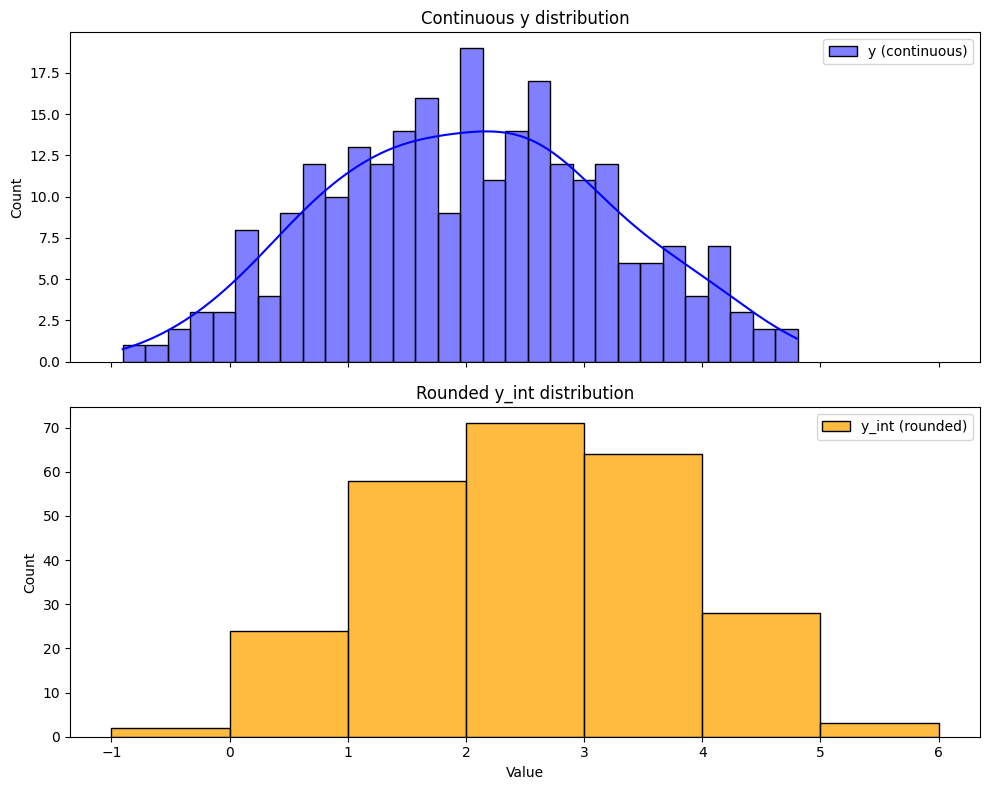

In [63]:
# ALL DEMANDS TOGETHER
y_vals = [pyo.value(model.y['demand', n, w]) for n in model.N for w in model.W]
y_int_vals = [pyo.value(model.y_int[n, w]) for n in model.N for w in model.W]

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.histplot(y_vals, kde=True, color='blue', label='y (continuous)', bins=30, ax=ax[0])
ax[0].legend()
ax[0].set_title('Continuous y distribution')

sns.histplot(y_int_vals, kde=False, color='orange', label='y_int (rounded)', 
             bins=range(int(min(y_int_vals)), int(max(y_int_vals))+2), ax=ax[1])
ax[1].legend()
ax[1].set_title('Rounded y_int distribution')

plt.xlabel('Value')
plt.tight_layout()
plt.show()

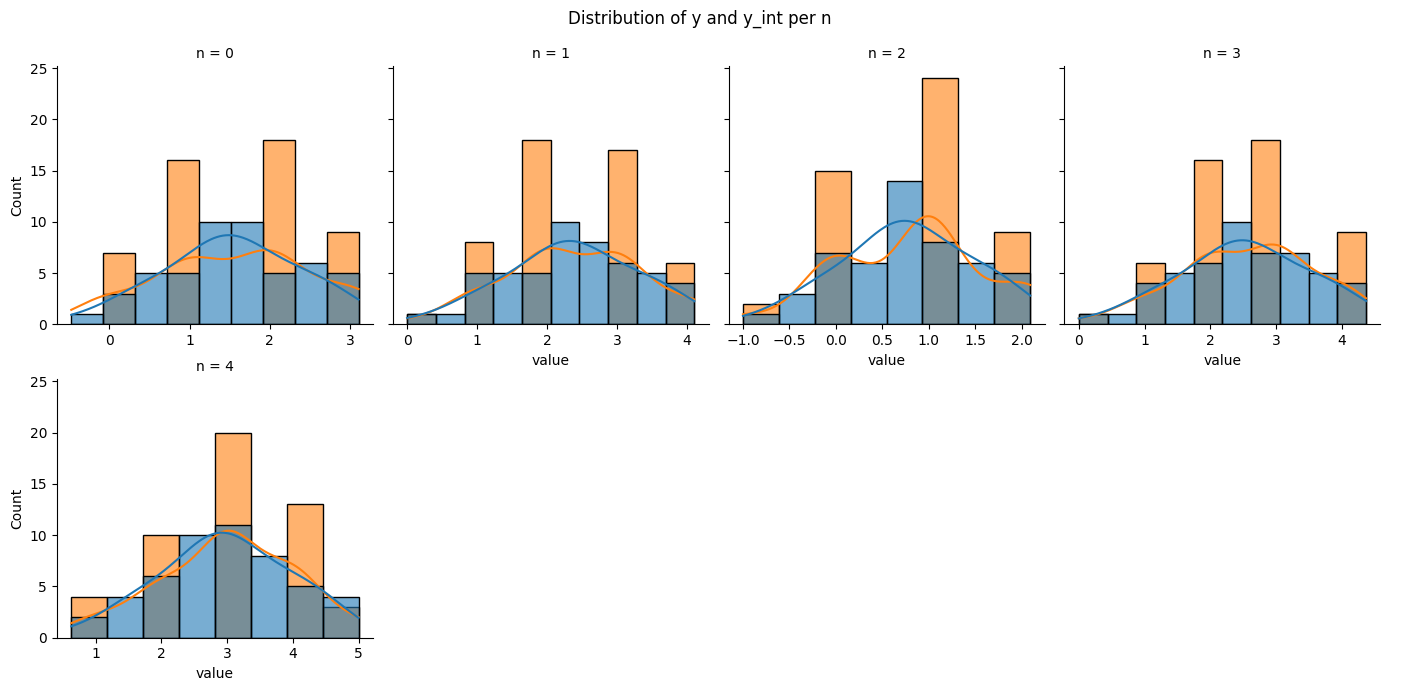

In [64]:
# DEMAND BY ID

# Create a DataFrame from your data
data = []
for n in model.N:
    for w in model.W:
        y_val = pyo.value(model.y['demand', n, w])
        y_int_val = pyo.value(model.y_int[n, w])
        data.append({'n': n, 'w': w, 'y': y_val, 'y_int': y_int_val})
df = pd.DataFrame(data)

# Melt the DataFrame to long format for seaborn
df_melted = df.melt(id_vars=['n', 'w'], value_vars=['y', 'y_int'], var_name='type', value_name='value')

# Plot using FacetGrid (one subplot per n)
g = sns.FacetGrid(df_melted, col='n', col_wrap=4, sharex=False, height=3.5)
g.map_dataframe(sns.histplot, x='value', hue='type', kde=True if 'y' in df_melted['type'].unique() else False, alpha=0.6)
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Distribution of y and y_int per n")
plt.show()


# EXPERIMENTS

In [73]:
import matplotlib.ticker as mticker
def experiment_price_n_sc_solve_time(trainer, use_means=True, n_ids=10,end_range=100):
    # Configuration
    test_ids = trainer.test_ids[:n_ids]  
    scenario_range = list(range(1, end_range, 5)) 

    filename = f"imgs/price_vs_n_sce_vs_solve_time_{'with_means' if use_means else 'no_means'}_{n_ids}_ids_{end_range}_n_sc.png"

    if os.path.exists(filename):
        print(f"Loading existing plot from {filename}")
        img = plt.imread(filename)
        plt.figure(figsize=(15, 16))
        plt.imshow(img)
        plt.axis('off')  # Hide axes
        plt.title("Loaded Plot Image")
        plt.show()
    else:
        # To store results
        results = []

        for i, test_id in enumerate(test_ids):
            print("&"*50)
            print(f"Processing ID: {test_id} ({i+1}/{len(test_ids)})")

            # --- Compute mean prices if needed ---
            if use_means:
                test_df = trainer.X.loc[trainer.test_indices]
                test_df = test_df[test_df['id'] == test_id]
                mean_price_by_id = test_df.mean()['price']
                mean_price_by_id = {0: mean_price_by_id}
                
                mean_price = test_df['price'].mean()
            else:
                mean_price = None
                mean_price_by_id = None
            
            # Build contextual_var for this single ID
            contextual_var = trainer.X[trainer.X['id'] == test_id]
            contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
            contextual_var.reset_index(drop=True, inplace=True)
            n_preds = 1  # Because we use one ID at a time

            for n_sc in scenario_range:
                # Define and solve model
                model = model_definition(contextual_var, n_sc, n_preds, mean_price=mean_price, mean_price_by_id=mean_price_by_id)
                const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand',
                            n_scenarios=n_sc, n_preds=n_preds)

                opt = pyo.SolverFactory('gurobi_direct')
                opt.options['threads'] = 0
                opt.options['NonConvex'] = 2

                start = time.time()
                results_obj = opt.solve(model, tee=False)
                end = time.time()

                price_val = pyo.value(model.x['price', 0])
                solve_time = end - start

                results.append({
                    'id': test_id,
                    'n': 0,
                    'n_sc': n_sc,
                    'price': price_val,
                    'solve_time': solve_time
                })
                print(f"n_sc={n_sc}: price={price_val:.4f}, time={solve_time:.4f}s")
            print("&"*50)

        # --- Convert to DataFrame ---
        df_results = pd.DataFrame(results)

        # --- Plot ---
        unique_ids = df_results['id'].unique()
        n_cols = 3
        n_rows = -(-len(unique_ids) // n_cols)  # Ceiling division

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharex=False)
        axes = axes.flatten()

        for i, test_id in enumerate(unique_ids):
            ax1 = axes[i]
            ax2 = ax1.twinx()  # Create second y-axis

            data = df_results[df_results['id'] == test_id]
            data['price'] = data['price'].round(4)


            # Plot price
            ax1.plot(data['n_sc'], data['price'], color='blue', marker='o', label='Price')
            #ax1.yaxis.set_major_formatter(mticker.ScalarFormatter(useOffset=False))

            ax1.set_ylabel('Price', color='blue')
            ax1.tick_params(axis='y', labelcolor='blue')
            ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))

            # Plot solve time
            ax2.plot(data['n_sc'], data['solve_time'], color='red', marker='x', label='Solve Time')
            ax2.set_ylabel('Solve Time (s)', color='red')
            ax2.tick_params(axis='y', labelcolor='red')

            ax1.set_title(f'ID: {test_id}')
            ax1.set_xlabel('Number of Scenarios (n_sc)')
            ax1.grid(True)

        # Remove unused subplots if any
        for j in range(i+1, len(axes)):
            fig.delaxes(axes[j])

        plt.suptitle("Price and Solve Time per ID", y=1.02)
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()

def experiment_solve_time_vs_n_preds(trainer, use_means=True, n_sc=50, end_range=10):
    # Configuration
    n_preds_range = list(range(1, end_range))

    filename = f"imgs/solve_time_vs_n_preds_{'with_means' if use_means else 'no_means'}.png"
    results = []
    if os.path.exists(filename):
        img = plt.imread(filename)
        plt.figure(figsize=(8, 5))
        plt.imshow(img)
        plt.axis('off')  # Hide axes
        plt.title("Loaded Plot Image")
        plt.show()
    else:
        for n_preds in n_preds_range:
            print(f"Running with n_preds = {n_preds}")

            # --- Define contextual_var ---
            ids = trainer.test_ids[:n_preds]
            contextual_var = trainer.X[trainer.X['id'].isin(ids)]
            contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
            contextual_var.reset_index(drop=True, inplace=True)

            # --- Compute mean prices if needed ---
            if use_means:
                test_df = trainer.X.loc[trainer.test_indices]
                test_df = test_df[test_df['id'].isin(ids)]
                mean_price_by_id = test_df.groupby('id')['price'].mean()
                #mean_price_by_id = mean_price_by_id.loc[ids]
                mean_price_by_id = dict(enumerate(mean_price_by_id))
                mean_price = test_df['price'].mean()
            else:
                mean_price = None
                mean_price_by_id = None

            try:
                model = model_definition(contextual_var, n_sc=n_sc, n_preds=n_preds,
                                        mean_price=mean_price, mean_price_by_id=mean_price_by_id)

                const_embed(model=trainer, opt_model=model, constaints=cons,
                            outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

                opt = pyo.SolverFactory('gurobi_direct')
                opt.options['threads'] = 0
                opt.options['NonConvex'] = 2

                start = time.time()
                results_obj = opt.solve(model, tee=False)
                end = time.time()
                solve_time = end - start

                results.append({'n_preds': n_preds, 'solve_time': solve_time})
                print(f"  Solve time = {solve_time:.2f} seconds")

            except Exception as e:
                print(f"  Error at n_preds = {n_preds}: {e}")
                results.append({'n_preds': n_preds, 'solve_time': None})

        # --- Convert to DataFrame ---
        df_results = pd.DataFrame(results)

        # --- Plot and Save ---
        plt.figure(figsize=(8, 5))
        plt.plot(df_results['n_preds'], df_results['solve_time'], marker='o', color='blue')
        plt.xlabel('Number of Prediction Points (n_preds)')
        plt.ylabel('Solve Time (seconds)')
        plt.title('Solve Time vs n_preds' + (' (with means)' if use_means else ' (no means)'))
        plt.grid(True)


        plt.tight_layout()
        plt.savefig(filename)
        plt.show()

        print(f"Plot saved to: {filename}")    

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 1 (1/10)
n_sc=1: price=20.7591, time=0.0176s
n_sc=6: price=20.7591, time=0.0172s
n_sc=11: price=20.7591, time=0.0175s
n_sc=16: price=20.7591, time=0.0188s
n_sc=21: price=20.7591, time=0.0206s
n_sc=26: price=20.7591, time=0.0206s
n_sc=31: price=20.7591, time=0.0212s
n_sc=36: price=20.7591, time=0.0210s
n_sc=41: price=20.7591, time=0.0210s
n_sc=46: price=20.7591, time=0.0272s
n_sc=51: price=20.7591, time=0.0225s
n_sc=56: price=20.7591, time=0.0243s
n_sc=61: price=20.7591, time=0.0273s
n_sc=66: price=20.7591, time=0.0261s
n_sc=71: price=20.7591, time=0.0301s
n_sc=76: price=20.7591, time=0.0269s
n_sc=81: price=20.7591, time=0.0279s
n_sc=86: price=20.7591, time=0.0299s
n_sc=91: price=20.7591, time=0.0301s
n_sc=96: price=20.7591, time=0.0300s
n_sc=101: price=20.7591, time=0.0318s
n_sc=106: price=20.7591, time=0.0324s
n_sc=111: price=20.7591, time=0.0333s
n_sc=116: price=20.7591, time=0.0346s
n_sc=121: price=20.7591, time=0.033

C:\Users\danie\AppData\Local\Temp\ipykernel_42172\1668504544.py:86: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['price'] = data['price'].round(4)


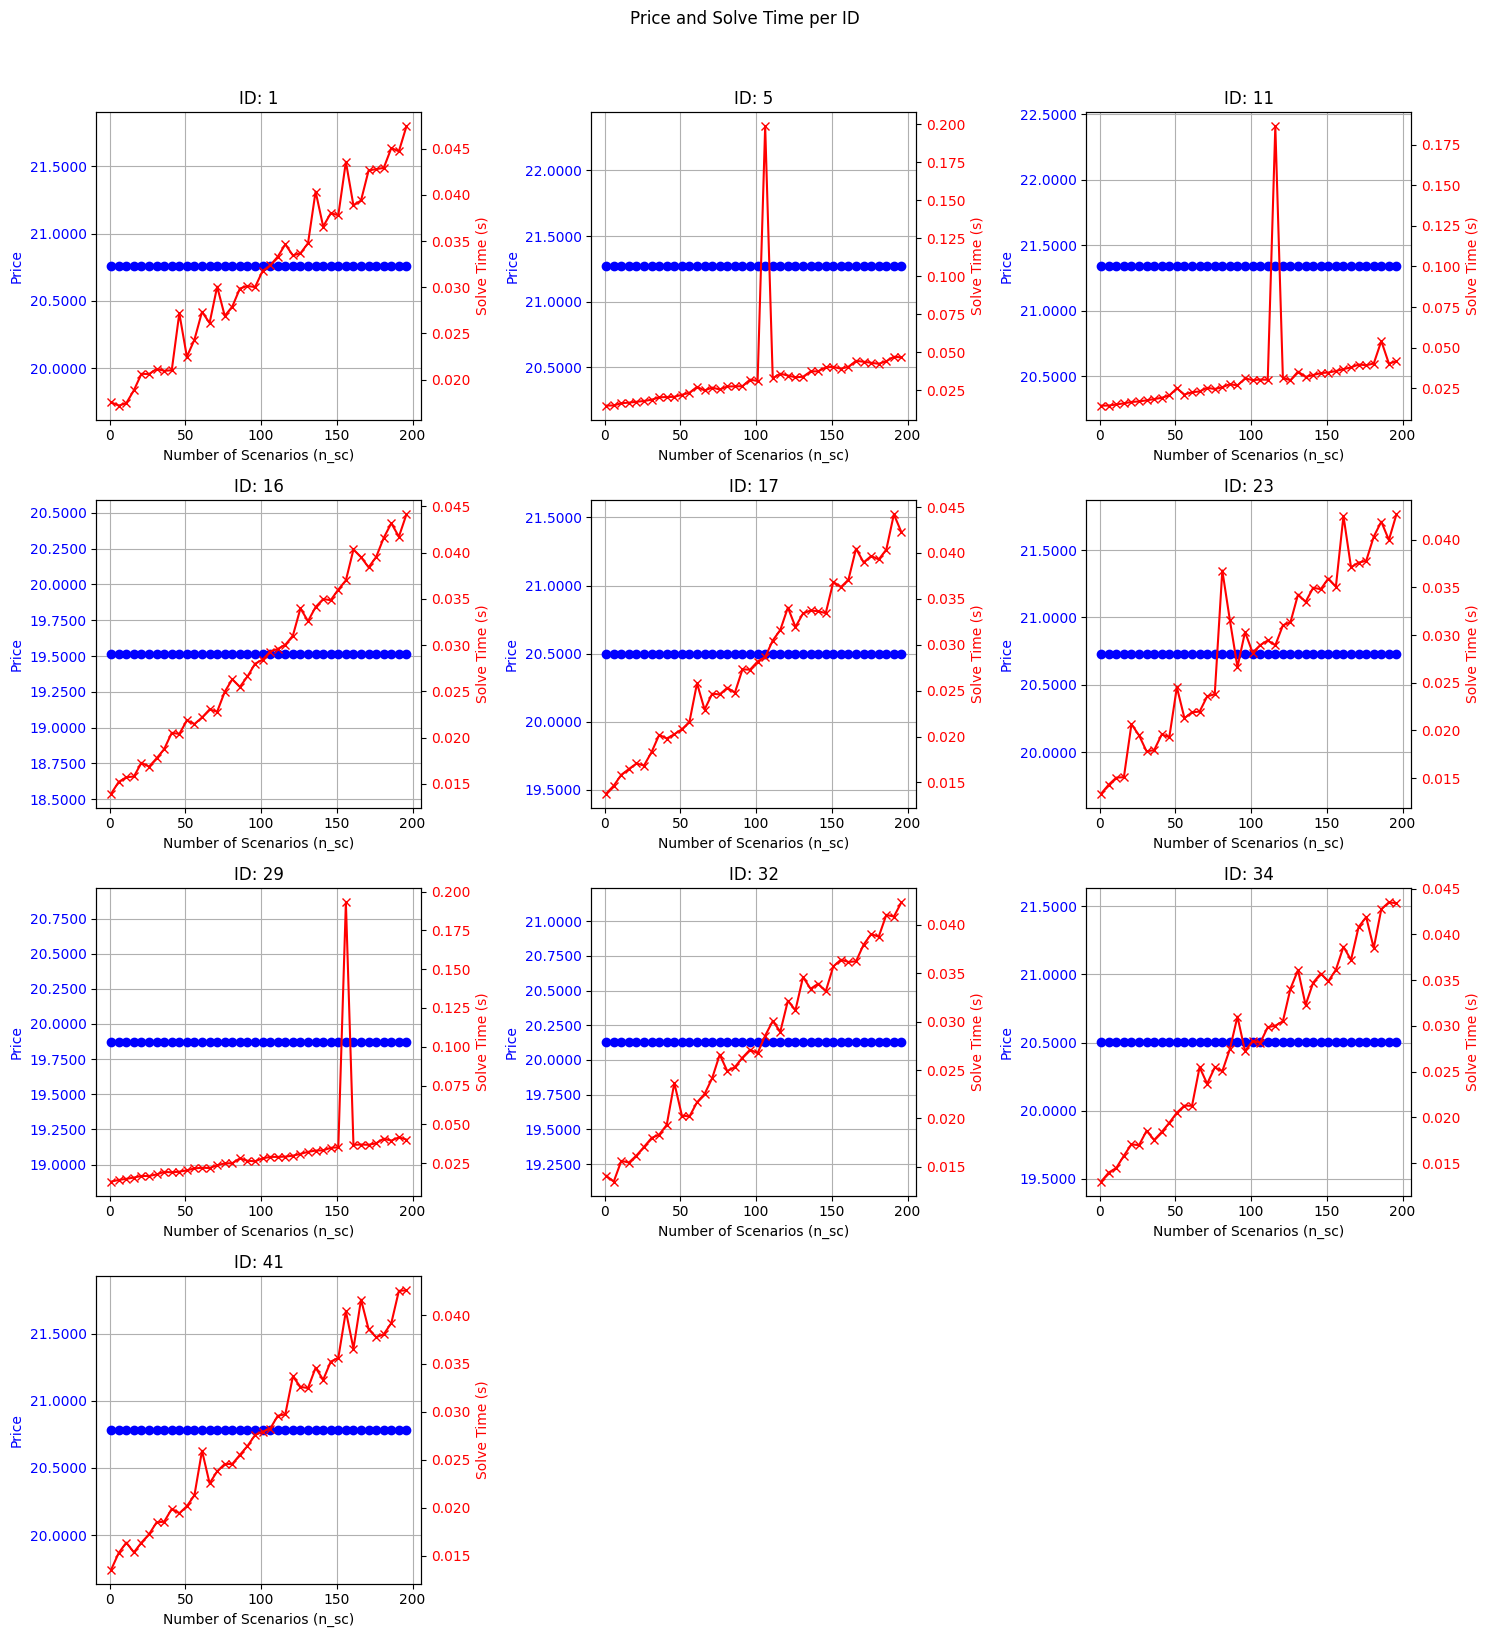

In [76]:
experiment_price_n_sc_solve_time(trainer, use_means=True, n_ids=10, end_range=200)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 1 (1/10)


n_sc=1: price=17.3053, time=0.0553s
n_sc=6: price=16.1560, time=0.1074s
n_sc=11: price=15.7003, time=0.0901s
n_sc=16: price=15.6517, time=0.0907s
n_sc=21: price=15.5170, time=0.0961s
n_sc=26: price=15.5557, time=0.0975s
n_sc=31: price=15.5564, time=0.1071s
n_sc=36: price=15.5196, time=0.1189s
n_sc=41: price=15.5209, time=0.1241s
n_sc=46: price=15.5170, time=0.1212s
n_sc=51: price=15.5203, time=0.1319s
n_sc=56: price=15.5170, time=0.1352s
n_sc=61: price=15.5241, time=0.1554s
n_sc=66: price=15.5242, time=0.1600s
n_sc=71: price=15.5178, time=0.1841s
n_sc=76: price=12.6566, time=0.1962s
n_sc=81: price=12.4668, time=0.1693s
n_sc=86: price=15.5138, time=0.1795s
n_sc=91: price=15.5177, time=0.2106s
n_sc=96: price=15.5243, time=0.2282s
n_sc=101: price=15.5243, time=0.2261s
n_sc=106: price=15.5241, time=0.2342s
n_sc=111: price=15.5170, time=0.2164s
n_sc=116: price=15.5170, time=0.2132s
n_sc=121: price=15.5337, time=0.2269s
n_sc=126: price=15.5213, time=0.2317s
n_sc=131: price=15.5213, time=0.25

C:\Users\danie\AppData\Local\Temp\ipykernel_42172\1668504544.py:86: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['price'] = data['price'].round(4)


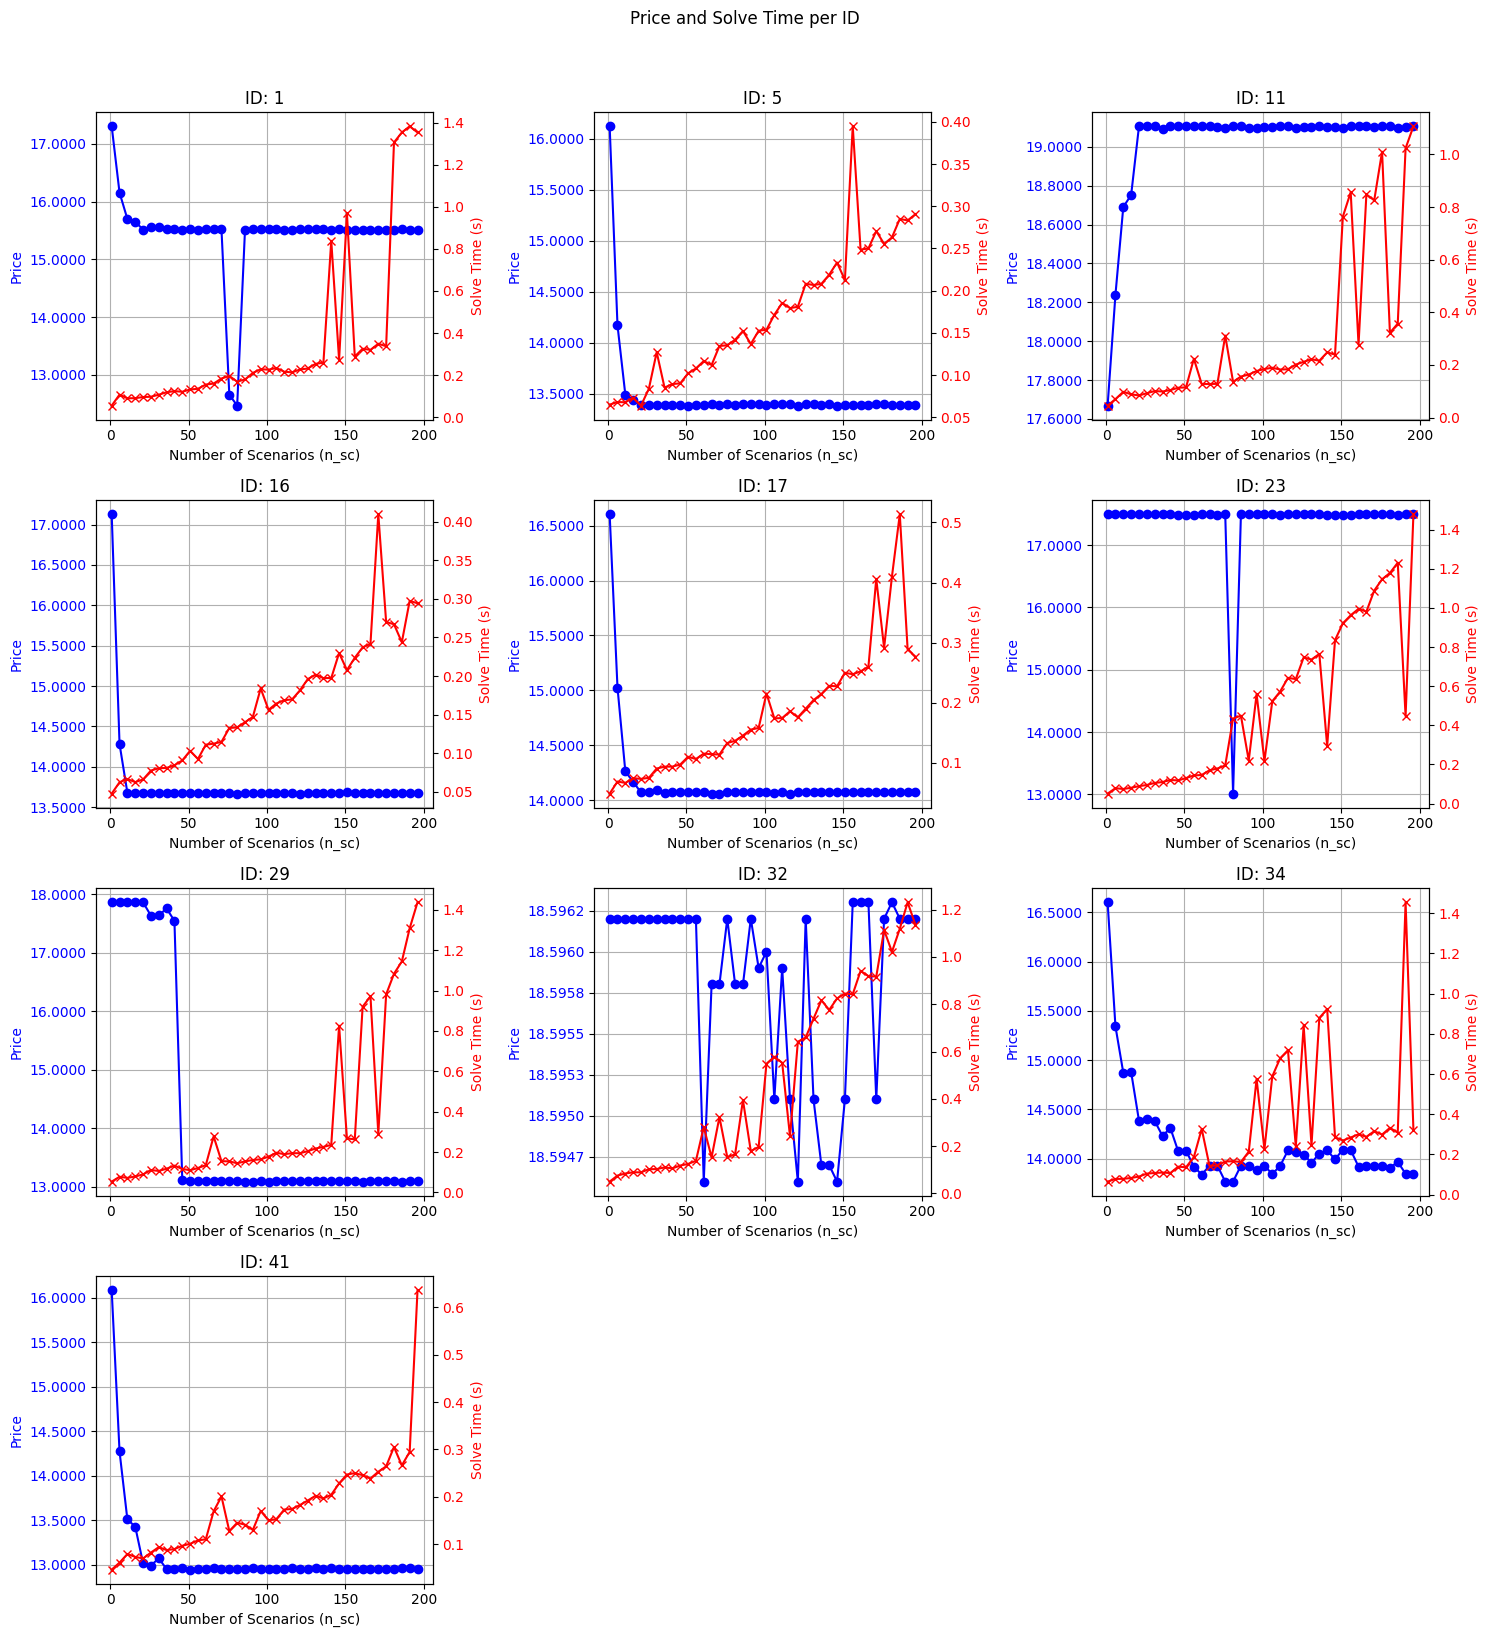

In [77]:
experiment_price_n_sc_solve_time(trainer, use_means=False, n_ids=10, end_range=200)

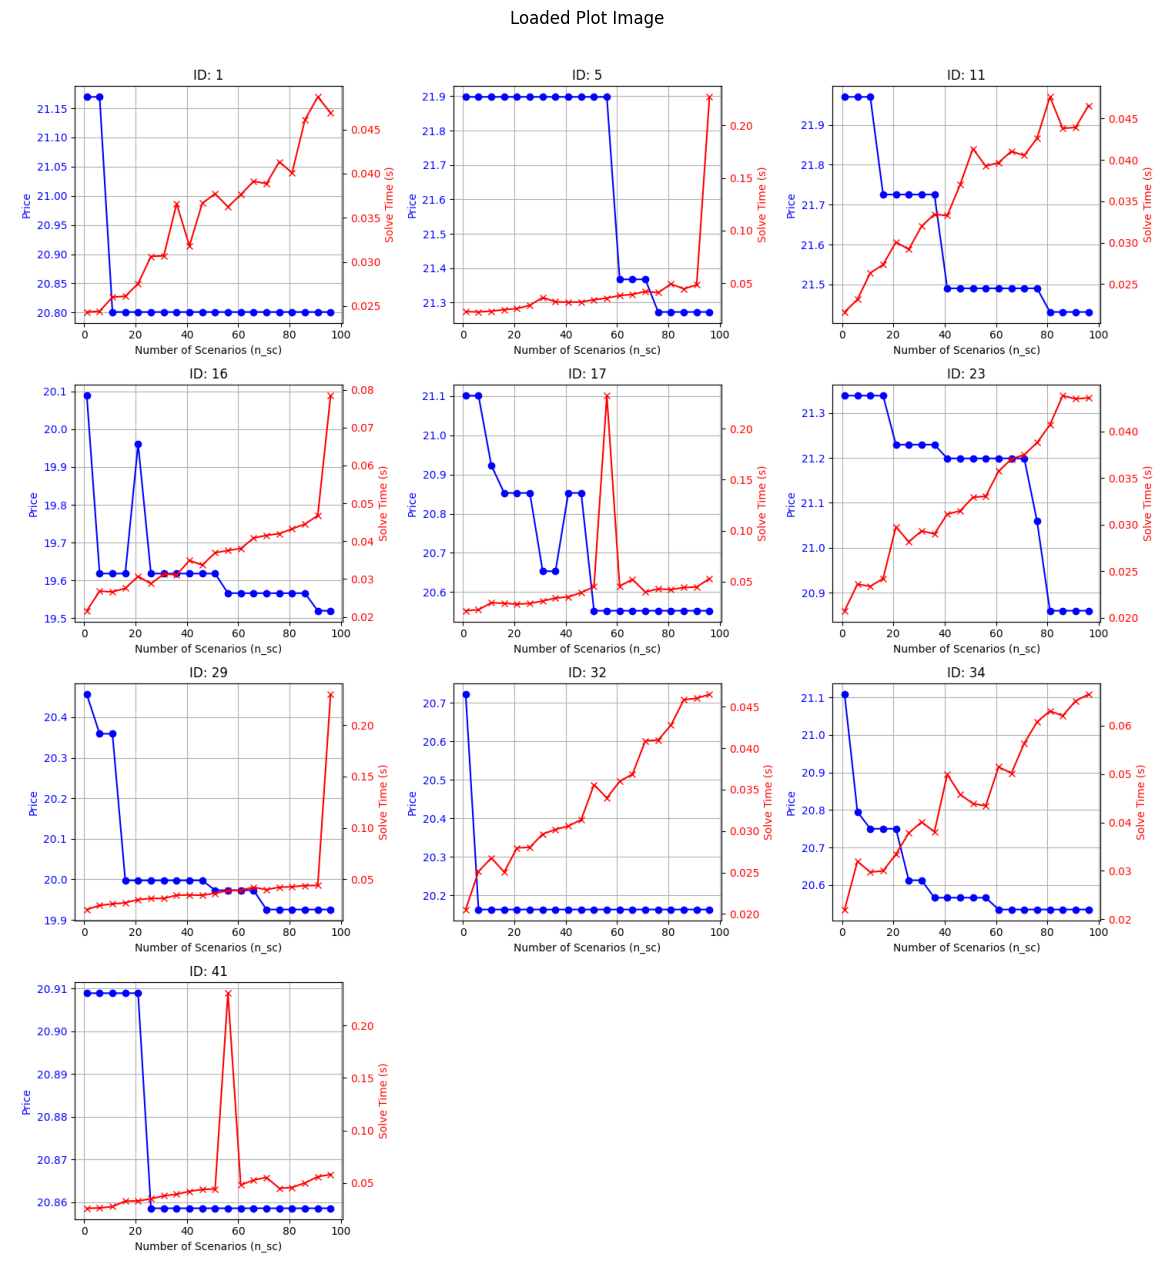

In [ ]:
'''# Configuration
test_ids = trainer.test_ids[:10]  # Try for first 5 test IDs
scenario_range = list(range(1, 100, 5))  # n_sc = 10, ..., 200
use_means = True

filename = f"imgs/price_vs_n_sce_vs_solve_time_{'with_means' if use_means else 'no_means'}.png"

if os.path.exists(filename):
    img = plt.imread(filename)
    plt.figure(figsize=(15, 16))
    plt.imshow(img)
    plt.axis('off')  # Hide axes
    plt.title("Loaded Plot Image")
    plt.show()
else:
    # To store results
    results = []

    for i, test_id in enumerate(test_ids):
        print("&"*50)
        print(f"Processing ID: {test_id} ({i+1}/{len(test_ids)})")

        # --- Compute mean prices if needed ---
        if use_means:
            test_df = trainer.X.loc[trainer.test_indices]
            test_df = test_df[test_df['id'] == test_id]
            mean_price_by_id = test_df.mean()['price']
            mean_price_by_id = {0: mean_price_by_id}
            
            mean_price = test_df['price'].mean()
        else:
            mean_price = None
            mean_price_by_id = None
        
        # Build contextual_var for this single ID
        contextual_var = trainer.X[trainer.X['id'] == test_id]
        contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
        contextual_var.reset_index(drop=True, inplace=True)
        n_preds = 1  # Because we use one ID at a time

        for n_sc in scenario_range:
            # Define and solve model
            model = model_definition(contextual_var, n_sc, n_preds, mean_price=mean_price, mean_price_by_id=mean_price_by_id)
            const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand',
                        n_scenarios=n_sc, n_preds=n_preds)

            opt = pyo.SolverFactory('gurobi_direct')
            opt.options['threads'] = 0
            opt.options['NonConvex'] = 2

            start = time.time()
            results_obj = opt.solve(model, tee=False)
            end = time.time()

            price_val = pyo.value(model.x['price', 0])
            solve_time = end - start

            results.append({
                'id': test_id,
                'n': 0,
                'n_sc': n_sc,
                'price': price_val,
                'solve_time': solve_time
            })
            print(f"n_sc={n_sc}: price={price_val:.4f}, time={solve_time:.4f}s")
        print("&"*50)

    # --- Convert to DataFrame ---
    df_results = pd.DataFrame(results)

    # --- Plot ---
    unique_ids = df_results['id'].unique()
    n_cols = 3
    n_rows = -(-len(unique_ids) // n_cols)  # Ceiling division

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharex=False)
    axes = axes.flatten()

    for i, test_id in enumerate(unique_ids):
        ax1 = axes[i]
        ax2 = ax1.twinx()  # Create second y-axis

        data = df_results[df_results['id'] == test_id]

        # Plot price
        ax1.plot(data['n_sc'], data['price'], color='blue', marker='o', label='Price')
        ax1.set_ylabel('Price', color='blue')
        ax1.tick_params(axis='y', labelcolor='blue')

        # Plot solve time
        ax2.plot(data['n_sc'], data['solve_time'], color='red', marker='x', label='Solve Time')
        ax2.set_ylabel('Solve Time (s)', color='red')
        ax2.tick_params(axis='y', labelcolor='red')

        ax1.set_title(f'ID: {test_id}')
        ax1.set_xlabel('Number of Scenarios (n_sc)')
        ax1.grid(True)

    # Remove unused subplots if any
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle("Price and Solve Time per ID", y=1.02)
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

'''

In [38]:
'''
# Configuration
n_preds_range = list(range(1, 10))  # n_preds = 1 to 20
n_sc = 50  # Fixed number of scenarios
use_means = True  # Toggle: True = pass mean_price_by_id to the model

filename = f"imgs/solve_time_vs_n_preds_{'with_means' if use_means else 'no_means'}.png"
results = []
if os.path.exists(filename):
    img = plt.imread(filename)
    plt.figure(figsize=(8, 5))
    plt.imshow(img)
    plt.axis('off')  # Hide axes
    plt.title("Loaded Plot Image")
    plt.show()
else:
    for n_preds in n_preds_range:
        print(f"Running with n_preds = {n_preds}")

        # --- Define contextual_var ---
        ids = trainer.test_ids[:n_preds]
        contextual_var = trainer.X[trainer.X['id'].isin(ids)]
        contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
        contextual_var.reset_index(drop=True, inplace=True)

        # --- Compute mean prices if needed ---
        if use_means:
            test_df = trainer.X.loc[trainer.test_indices]
            test_df = test_df[test_df['id'].isin(ids)]
            mean_price_by_id = test_df.groupby('id')['price'].mean()
            #mean_price_by_id = mean_price_by_id.loc[ids]
            mean_price_by_id = dict(enumerate(mean_price_by_id))
            mean_price = test_df['price'].mean()
        else:
            mean_price = None
            mean_price_by_id = None

        try:
            model = model_definition(contextual_var, n_sc=n_sc, n_preds=n_preds,
                                    mean_price=mean_price, mean_price_by_id=mean_price_by_id)

            const_embed(model=trainer, opt_model=model, constaints=cons,
                        outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

            opt = pyo.SolverFactory('gurobi_direct')
            opt.options['threads'] = 0
            opt.options['NonConvex'] = 2

            start = time.time()
            results_obj = opt.solve(model, tee=False)
            end = time.time()
            solve_time = end - start

            results.append({'n_preds': n_preds, 'solve_time': solve_time})
            print(f"  Solve time = {solve_time:.2f} seconds")

        except Exception as e:
            print(f"  Error at n_preds = {n_preds}: {e}")
            results.append({'n_preds': n_preds, 'solve_time': None})

    # --- Convert to DataFrame ---
    df_results = pd.DataFrame(results)

    # --- Plot and Save ---
    plt.figure(figsize=(8, 5))
    plt.plot(df_results['n_preds'], df_results['solve_time'], marker='o', color='blue')
    plt.xlabel('Number of Prediction Points (n_preds)')
    plt.ylabel('Solve Time (seconds)')
    plt.title('Solve Time vs n_preds' + (' (with means)' if use_means else ' (no means)'))
    plt.grid(True)


    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

    print(f"Plot saved to: {filename}")
'''

'\n# Configuration\nn_preds_range = list(range(1, 10))  # n_preds = 1 to 20\nn_sc = 50  # Fixed number of scenarios\nuse_means = True  # Toggle: True = pass mean_price_by_id to the model\n\nfilename = f"imgs/solve_time_vs_n_preds_{\'with_means\' if use_means else \'no_means\'}.png"\nresults = []\nif os.path.exists(filename):\n    img = plt.imread(filename)\n    plt.figure(figsize=(8, 5))\n    plt.imshow(img)\n    plt.axis(\'off\')  # Hide axes\n    plt.title("Loaded Plot Image")\n    plt.show()\nelse:\n    for n_preds in n_preds_range:\n        print(f"Running with n_preds = {n_preds}")\n\n        # --- Define contextual_var ---\n        ids = trainer.test_ids[:n_preds]\n        contextual_var = trainer.X[trainer.X[\'id\'].isin(ids)]\n        contextual_var = contextual_var.drop_duplicates(subset=\'id\', keep=\'first\').drop(columns=\'id\')\n        contextual_var.reset_index(drop=True, inplace=True)\n\n        # --- Compute mean prices if needed ---\n        if use_means:\n           